# Travel Booking Fraud Review – CRISP-DM
**Course:** Data Science for Business (DATDRD05-T03) · **Group 7 – Fraud 3** · Alberto Barrionuevo Vargas-Machuca, Anisah Sutrisno, Kyran Weijman

Dataset: **group_07_fraud_3.csv**.

**Convention used throughout:** we label each statement as **[Scenario]** (given by the case, not verified), **[Data]** (shown by visible code/output) or **[Choice]** (our own analytical decision).

## Phase 1 – Business Understanding

### 1.1 Business problem
**[Scenario]** A travel booking business wants to find fraudulent bookings/transactions. Fraud is rare, and each fraudulent booking leads to losses after it is investigated. The business cannot manually review every transaction, so it needs a way to prioritise which transactions are reviewed first.

### 1.2 Stakeholder / user
- Primary user: the fraud review team (analysts who open the cases and decide).
- Decision owner: fraud/risk manager (sets the review capacity and accepts the trade-off between cost of review and fraud losses).
- Affected: genuine customers (a false alarm means delay, friction or a blocked booking) and finance (fraud losses, chargebacks).

### 1.3 Decision
For each new transaction: send it to manual review, or let it go through automatically. The model does not decide fraud; it ranks transactions so that limited review time goes to the riskiest ones.

### 1.4 Prediction / decision moment
Right after a booking transaction is made and before it is confirmed/fulfilled. Only information known at that moment can be used (amount, customer history, account age, channel, country, hour, device age, recent activity).
Information that appears after the decision is not available then, so it cannot be a predictor (candidate leakage, to be verified in Phase 2).

### 1.5 Scope
- In scope: one binary prediction (fraud_flag: fraud / not fraud) for transactions in the supplied dataset, producing a risk score and a review list.
- Out of scope: automatic blocking of customers, legal/chargeback process, building the investigation workflow, causes of fraud beyond what the data shows.

### 1.6 Measurable success criteria
Accuracy is not a valid criterion: with very few frauds, a model that says "everything is legitimate" is almost always "right".
We will judge success against a baseline, using review capacity:
1. Primary: share of all fraud cases found in the top *X*% highest-risk transactions (recall at top *X*% review capacity), compared with the baseline "no model" (random review finds about *X*% of fraud) and a majority-class baseline (finds none).
2. Secondary: ROC AUC (ranking quality) and precision at the same cutoff (how many reviewed cases are really fraud; workload and customer friction).
3. Stability: the cutoff must behave similarly in train and test (e.g. share of transactions above the threshold does not change a lot).
4. Minimum bar for use: clearly better than random review on the test set.Review capacity assumption [Choice]: the case gives no real capacity, so we state one: the team can manually review 5% of transactions (X = 5). Why 5%: the brief asks us to evaluate under a stated capacity; the fraud rate in the file is 32/3,203 = around 1.0%, so 5% is about five times the fraud rate, enough room to include fraud plus false alarms, but still a real limit; in a test set of about 960 rows, 5% is about 48 reviews. For robustness we will also report 2% and 10%.

### 1.7 Costs of errors (business view)
- Missed fraud (false negative): direct financial loss, possible chargeback, reputational damage.
- False alarm (false positive): analyst time wasted and a genuine customer delayed or annoyed.
- With 1% fraud, even a good model produces many false alarms per real fraud found, so the review capacity limit matters more than a single "accuracy" number.
- No real cost figures are given. We will not invent them, we will compare alternatives qualitatively or with clearly labelled assumptions.

### 1.8 Critical assessment of scenario assumptions
| Assumption in the scenario | Why it may be wrong / limited | How we handle it |
|---|---|---|
| The label fraud_flag equals true fraud | It may only reflect cases that were detected/investigated; undetected fraud is labelled legitimate | Treat results as "detected fraud"; mention as limitation |
| Data is about travel bookings | [Data (to be shown in Phase 2)] first inspection suggests the columns are generic payment/account fields, none seems to describe a trip . Evidence (df.columns) is shown in Phase 2 | Until then, do not claim travel-specific patterns (confirm in Phase 2) |
| Past patterns will repeat | Fraudsters adapt, the model can age quickly | Monitoring and refresh in Phase 6 |
| Manual review is possible for some fraction | The real capacity and cost per review are unknown | State an assumed *X*% and test sensitivity |
| Post-investigation fields are usable | They are only known after the decision: leakage | Exclude them from predictors, justify with evidence in Phase 2 |
| Very few fraud cases | Results can be unstable (a handful of cases changes recall a lot) | Stratified split, report counts not only percentages, be cautious in claims |


## Phase 2 – Data Understanding
**Goal**: know what one row is, what the target is, how reliable the data is, which patterns exist and which columns must not be used. Every number quoted in the text comes from a visible cell below.

### 2.1 Load the data and first look

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

df = pd.read_csv('group_07_fraud_3.csv')
print('Shape (rows, columns):', df.shape)
print('\nColumns:', list(df.columns))
print('\nData types:')
print(df.dtypes)
df.head()

Shape (rows, columns): (3203, 12)

Columns: ['transaction_id', 'amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h', 'channel', 'country', 'hour', 'device_age_days', 'fraud_flag', 'post_investigation_loss_eur', 'chargeback_confirmed_after_60d']

Data types:
transaction_id                        str
amount_eur                        float64
customer_avg_amount_30d           float64
account_age_days                    int64
previous_transactions_24h           int64
channel                               str
country                               str
hour                                int64
device_age_days                     int64
fraud_flag                          int64
post_investigation_loss_eur       float64
chargeback_confirmed_after_60d      int64
dtype: object


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
0,TX30000000,29.40,38.19,1721,6,Online,ES,17,930,0,0.0,0
1,TX30000001,85.71,81.98,1731,3,app,DE,5,326,0,0.0,0
2,TX30000002,45.36,180.96,2098,2,app,DE,17,1030,0,0.0,0
3,TX30000003,72.43,61.92,1646,2,online,NL,15,594,0,0.0,0
4,TX30000004,94.67,45.00,833,2,app,FR,22,202,0,0.0,0


Variable dictionary. No data dictionary was supplied, so the meanings below are **[Assumption]** inferred from the column names, not verified facts.

| Column | Assumed meaning | Type | Known at decision moment? |
|---|---|---|---|
| transaction_id | Identifier of the transaction | text (key) | Yes, identifier only, not a predictor |
| amount_eur | Transaction amount in EUR | numeric | Yes |
| customer_avg_amount_30d | Customer's average amount over the previous 30 days | numeric | Yes, if it excludes the current transaction (to be assumed, cannot be checked) |
| account_age_days | Age of the account in days | numeric | Yes |
| previous_transactions_24h | Number of transactions in the previous 24 h | numeric | Yes, if it excludes the current one |
| channel | Sales channel (online / app / store) | categorical | Yes |
| country | Country code (ES, BE, FR, DE, NL, UK) | categorical | Yes |
| hour | Hour of the day (0–23) | numeric | Yes |
| device_age_days | Age of the device in days | numeric | Yes |
| fraud_flag | Target: 1 = fraud, 0 = legitimate | binary | No, it is the outcome |
| post_investigation_loss_eur | Loss recorded after investigation | numeric | No, by name, it exists only after the investigation |
| chargeback_confirmed_after_60d | Chargeback confirmed 60 days later | binary | No, by name, it is known only 60 days later |

Evidence for the travel assumption from Phase 1: the column list above contains no trip-related field. The data describe generic payment/account behaviour, so we treat the problem as transaction fraud and will not claim travel-specific findings.

### 2.2 Observation unit, key and target

In [2]:
# Key: is transaction_id unique?
print('Rows:', len(df))
print('Unique transaction_id:', df['transaction_id'].nunique())
print('Fully duplicated rows:', df.duplicated().sum())
print('Duplicated transaction_id:', df['transaction_id'].duplicated().sum())

print('\nRows whose transaction_id appears more than once:')
display(df[df['transaction_id'].duplicated(keep=False)].sort_values('transaction_id'))

# Target
print('Target fraud_flag (counts):')
print(df['fraud_flag'].value_counts())
print('\nFraud rate: %.2f%%' % (100 * df['fraud_flag'].mean()))
print('Legitimate per fraud case: %.0f' % ((df['fraud_flag'] == 0).sum() / df['fraud_flag'].sum()))

Rows: 3203
Unique transaction_id: 3200
Fully duplicated rows: 3
Duplicated transaction_id: 3

Rows whose transaction_id appears more than once:


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
476,TX30000476,52.36,36.28,260,3,app,FR,19,1064,0,0.0,0
3201,TX30000476,52.36,36.28,260,3,app,FR,19,1064,0,0.0,0
2597,TX30002597,25.42,45.31,1592,2,online,DE,2,31,0,0.0,0
3200,TX30002597,25.42,45.31,1592,2,online,DE,2,31,0,0.0,0
3052,TX30003052,226.00,72.10,2100,1,app,DE,1,199,0,0.0,0
3202,TX30003052,226.00,72.10,2100,1,app,DE,1,199,0,0.0,0


Target fraud_flag (counts):
fraud_flag
0    3171
1      32
Name: count, dtype: int64

Fraud rate: 1.00%
Legitimate per fraud case: 99


**What the output shows**
- Observation unit: one row = one transaction (booking payment). Key: transaction_id.
- The key is not perfectly unique: 3,203 rows but 3,200 unique IDs. The 3 repeated IDs (TX30000476, TX30002597, TX30003052) are exact copies of an earlier row, and the copies sit at the very end of the file, so they look like accidental duplicates, not new transactions. All 3 are legitimate. Duplicates would count the same event twice, so they will be removed in Phase 3.
- Target: 32 frauds vs 3,171 legitimate = 1.00% (about 99 legitimate per fraud). This is a strong rare event problem. A model that always says "legitimate" would be 99.0% accurate and find 0 frauds, confirming why accuracy is not our metric.
- Limitation: 32 positives is very few. Any rate, split or metric based on them will be noisy.

### 2.3 Data quality: missing, invalid and inconsistent values

In [3]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])

print('\nMissing amount_eur by class (share of each class):')
print(df.assign(amount_missing=df['amount_eur'].isna()).groupby('fraud_flag')['amount_missing'].agg(['sum', 'mean']))

print('\nImpossible values:')
print('amount_eur <= 0           :', (df['amount_eur'] <= 0).sum())
print('account_age_days < 0      :', (df['account_age_days'] < 0).sum())
print('device_age_days < 0       :', (df['device_age_days'] < 0).sum())
print('hour outside 0-23         :', (~df['hour'].between(0, 23)).sum())
print('Rows with account_age_days < 0:')
display(df[df['account_age_days'] < 0])

print('\nchannel – raw labels:')
print(df['channel'].value_counts())
print('\nchannel – after lower-case + strip:')
print(df['channel'].str.lower().str.strip().value_counts())

print('\ncountry labels:')
print(df['country'].value_counts())

Missing values per column:
amount_eur    20
dtype: int64

Missing amount_eur by class (share of each class):
            sum      mean
fraud_flag               
0            19  0.005992
1             1  0.031250

Impossible values:
amount_eur <= 0           : 0
account_age_days < 0      : 4
device_age_days < 0       : 0
hour outside 0-23         : 0
Rows with account_age_days < 0:


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
183,TX30000183,50.52,36.56,-27,2,store,FR,15,314,0,0.0,0
348,TX30000348,656.76,33.12,-20,3,store,BE,8,936,0,0.0,0
2118,TX30002118,114.76,32.47,-27,0,app,FR,17,755,0,0.0,0
2170,TX30002170,34.90,38.29,-28,3,store,FR,9,264,0,0.0,0



channel – raw labels:
channel
app       1019
online     948
store      636
Online     280
APP        219
ONLINE     101
Name: count, dtype: int64

channel – after lower-case + strip:
channel
online    1329
app       1238
store      636
Name: count, dtype: int64

country labels:
country
ES    580
BE    569
FR    526
DE    517
NL    514
UK    497
Name: count, dtype: int64


**What the output shows**
- Missing values: only "amount_eur" (20 rows, 0.6%). It is the most important variable, so we must not ignore it. 1 of the 20 is a fraud case 3.1% versus (0.6%) among legitimate rows. With a single fraud case we cannot conclude that missingness is related to fraud, but we also cannot rule it out, so Phase 3 should keep an indicator of missingness or at least check it.
- Impossible values: 4 rows have a negative "account_age_days" (−20 to −28), which is impossible for an account age. All 4 are legitimate. Likely an entry or timing error. No other impossible values (no amount ≤ 0, hours all in 0–23, no negative device age).
- Inconsistent categories: "channel" has 6 labels for 3 real channels (Online, ONLINE, online; APP, app; store). After lower-casing: online 1,329, app 1,238, store 636. Without cleaning, a model would treat "app" and "APP" as different channels.
- "country" is clean (6 consistent codes).

### 2.4 Distributions of the numeric variables

                            count     mean     std    min     25%      50%      75%      max
amount_eur                 3183.0   100.03  119.30   1.72   30.58    61.46   119.48  1698.57
customer_avg_amount_30d    3203.0    61.47   44.16   4.99   32.43    49.19    77.07   436.78
account_age_days           3203.0  1251.24  718.61 -28.00  633.00  1253.00  1877.50  2498.00
previous_transactions_24h  3203.0     2.39    1.57   0.00    1.00     2.00     3.00    10.00
hour                       3203.0    11.45    6.85   0.00    6.00    12.00    17.00    23.00
device_age_days            3203.0   587.97  350.39   0.00  289.00   576.00   898.00  1199.00

Skewness (0 = symmetric):
amount_eur                   3.63
customer_avg_amount_30d      2.12
account_age_days             0.01
previous_transactions_24h    0.67
hour                        -0.02
device_age_days              0.04
dtype: float64

amount_eur IQR upper fence: 252.8
Rows above the fence: 248
Fraud cases above the fence: 6 of 32


Text(0.5, 0, 'hour')

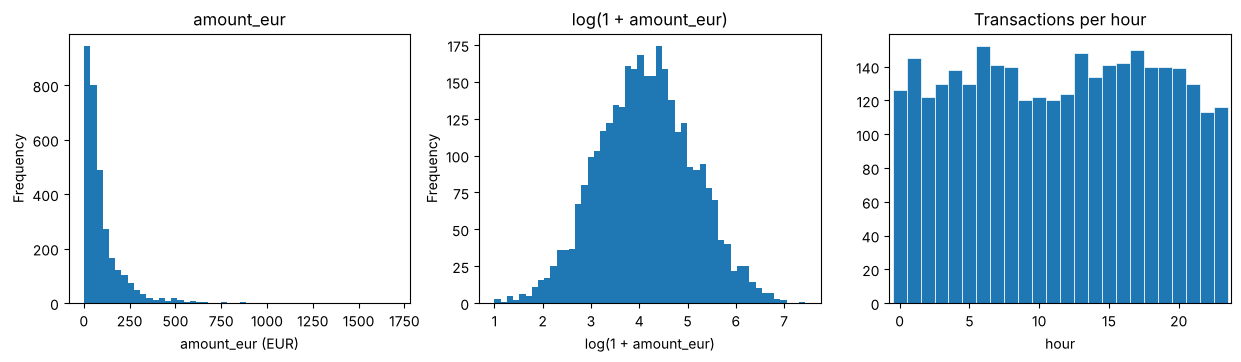

In [4]:
num_cols = ['amount_eur', 'customer_avg_amount_30d', 'account_age_days',
            'previous_transactions_24h', 'hour', 'device_age_days']
print(df[num_cols].describe().T.round(2))
print('\nSkewness (0 = symmetric):')
print(df[num_cols].skew().round(2))

# Outliers in amount_eur with the IQR rule
q1, q3 = df['amount_eur'].quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
print('\namount_eur IQR upper fence: %.1f' % upper)
print('Rows above the fence:', (df['amount_eur'] > upper).sum())
print('Fraud cases above the fence:', ((df['amount_eur'] > upper) & (df['fraud_flag'] == 1)).sum(), 'of', df['fraud_flag'].sum())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))

df['amount_eur'].plot.hist(bins=50, ax=ax[0], title='amount_eur')
ax[0].set_xlabel('amount_eur (EUR)')

np.log1p(df['amount_eur']).plot.hist(bins=50, ax=ax[1], title='log(1 + amount_eur)')
ax[1].set_xlabel('log(1 + amount_eur)')

# One bar per hour, bars touching, x-axis labels every 5 hours starting at 0
df['hour'].value_counts().sort_index().plot.bar(ax=ax[2], width=1.0, edgecolor='white', linewidth=0.5,
                                                title='Transactions per hour')
ax[2].set_xticks(range(0, 24, 5))
ax[2].set_xticklabels(range(0, 24, 5), rotation=0)
ax[2].set_xlabel('hour')

**What the output shows**
- "amount_eur" is strongly right-skewed (skewness 3.63; median 61.5 vs mean 100.0). "customer_avg_amount_30d" is also skewed (2.12). A log transformation makes "amount_eur" more symmetric, which helps linear models.
- 248 rows (7.7%) are above the IQR fence (252.8), but only 6 of the 32 frauds (19%). So high amount alone does not identify most frauds, and we should not delete high amounts as outliers: they include real frauds and plausible expensive bookings.
- "account_age_days", "device_age_days" and "hour" are roughly symmetric/uniform.

### 2.5 Patterns: how do fraud and legitimate transactions differ?
With only a few dozen fraud cases, every share below is shown together with its counts.

In [5]:
d = df.copy()
d['channel_clean'] = d['channel'].str.lower().str.strip()
d['amount_vs_usual'] = d['amount_eur'] / d['customer_avg_amount_30d']

print('Median by class:')
print(d.groupby('fraud_flag')[['amount_eur', 'customer_avg_amount_30d', 'amount_vs_usual',
                               'account_age_days', 'previous_transactions_24h',
                               'hour', 'device_age_days']].median().round(2).T)

def rate_table(col):
    t = d.groupby(col)['fraud_flag'].agg(rows='size', frauds='sum')
    t['fraud_rate_%'] = (100 * t['frauds'] / t['rows']).round(2)
    return t

d['hour_band'] = pd.cut(d['hour'], [-1, 5, 11, 17, 23], labels=['00-05', '06-11', '12-17', '18-23'])
d['new_account_30d'] = d['account_age_days'] <= 30
d['amount_x_usual_band'] = pd.cut(d['amount_vs_usual'], [0, 1, 2, 4, np.inf], labels=['<=1x', '1-2x', '2-4x', '>4x'])

parts = []
for col in ['hour_band', 'channel_clean', 'country', 'new_account_30d', 'amount_x_usual_band']:
    t = rate_table(col)
    t.index = pd.MultiIndex.from_product([[col], t.index.astype(str)],
                                         names=['variable', 'group'])
    parts.append(t)

print('Fraud rate by segment (rows = transactions, frauds = fraud cases):')
display(pd.concat(parts))

Median by class:
fraud_flag                       0        1
amount_eur                   61.08   117.97
customer_avg_amount_30d      49.34    38.58
amount_vs_usual               1.20     2.94
account_age_days           1253.00  1296.50
previous_transactions_24h     2.00     2.00
hour                         12.00     6.00
device_age_days             577.00   555.00
Fraud rate by segment (rows = transactions, frauds = fraud cases):


rows  frauds  fraud_rate_%
variable            group                             
hour_band           00-05    791      14          1.77
                    06-11    795       5          0.63
                    12-17    839       6          0.72
                    18-23    778       7          0.90
channel_clean       app     1238      14          1.13
                    online  1329      14          1.05
                    store    636       4          0.63
country             BE       569      10          1.76
                    DE       517       9          1.74
                    ES       580       4          0.69
                    FR       526       4          0.76
                    NL       514       3          0.58
                    UK       497       2          0.40
new_account_30d     False   3159      30          0.95
                    True      44       2          4.55
amount_x_usual_band <=1x    1374       7          0.51
                    1-2x     719       3          0.42
                    2-4x     591      10          1.69
                    >4x      499      11          2.20

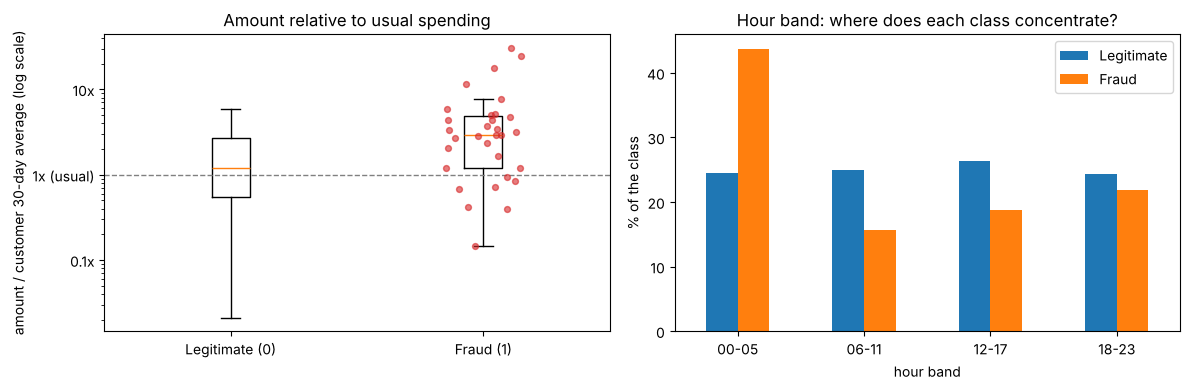

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rng = np.random.default_rng(0)  # fixed seed so the jitter is reproducible

legit = d.loc[d['fraud_flag'] == 0, 'amount_vs_usual'].dropna()
fraud = d.loc[d['fraud_flag'] == 1, 'amount_vs_usual'].dropna()

# Left: amount relative to the customer's usual amount (log scale)
ax[0].boxplot([legit, fraud], showfliers=False)
ax[0].set_xticks([1, 2])
ax[0].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
ax[0].scatter(2 + rng.uniform(-0.15, 0.15, len(fraud)), fraud,
              s=18, alpha=0.6, color='tab:red', zorder=3)   # each red dot = 1 fraud
ax[0].set_yscale('log')
ax[0].set_yticks([0.1, 1, 10])
ax[0].set_yticklabels(['0.1x', '1x (usual)', '10x'])
ax[0].axhline(1, ls='--', color='grey', lw=1)               # 1 = exactly the usual amount
ax[0].set_ylabel('amount / customer 30-day average (log scale)')
ax[0].set_title('Amount relative to usual spending')

# Right: share of each class in every hour band
share = pd.crosstab(d['hour_band'], d['fraud_flag'], normalize='columns') * 100
share.columns = ['Legitimate', 'Fraud']
share.plot.bar(ax=ax[1], rot=0)
ax[1].set_xlabel('hour band')
ax[1].set_ylabel('% of the class')
ax[1].set_title('Hour band: where does each class concentrate?')

plt.tight_layout()
plt.show()

What the tables and plots show (counts in brackets; with 32 frauds, differences between small groups are suggestive, not proven)

- Amount relative to the customer's usual spending is the clearest signal.In the left plot, 1× (dashed line) means "exactly the usual amount" and the axis is logarithmic, so each tick is 10 times the previous one. The median ratio is 2.94 for frauds vs 1.20 for legitimate transactions. Transactions above 2× the usual amount hold 21 of the 31 frauds with a known amount (68%) but only about a third of the rows. The fraud rate rises from about 0.4–0.5% to 1.7–2.2% (above 2×). The raw amount alone identifies few frauds (only 6 of 32 are above the IQR fence, see 2.4), so the *ratio* carries information that the raw amount does not.
- This signal is not a clean separator. The boxes of the two classes overlap, and 7 of the 31 frauds are at or below their customer's usual amount (band "<=1x"). On the other hand, several frauds are 10–30 times the usual amount. It helps to rank risk, but it does not decide on its own.
- Night hours: in the right plot, legitimate transactions are spread evenly over the four hour bands (about 25% each), while 44% of the frauds (14 of 32) happen between 00 and 05 h. The fraud rate of that band is 1.77% (791 rows) vs 0.63–0.90% in the others.
- Country: BE (1.76%) and DE (1.74%) are about 2–4× higher than ES, FR, NL, UK (0.40–0.76%); together they hold 19 of 32 frauds. This may be real or chance; to be treated with caution (country as a feature carries fairness and stability concerns).
- New accounts (≤ 30 days): 4.55% fraud rate, but that is only 2 frauds in 44 rows, too small to rely on.
- Channel shows no clear difference (app 1.13%, online 1.05%, store 0.63%).
- account_age_days, device_age_days, previous_transactions_24h: medians are nearly identical between classes, so they look weak on their own.

### 2.6 Leakage check: columns that may not be known at the decision moment

In [7]:
print('chargeback_confirmed_after_60d vs fraud_flag:')
print(pd.crosstab(df['fraud_flag'], df['chargeback_confirmed_after_60d']))

print('\npost_investigation_loss_eur > 0 vs fraud_flag:')
print(pd.crosstab(df['fraud_flag'], df['post_investigation_loss_eur'] > 0))

print('\nLoss among fraud cases (EUR):')
print(df.loc[df['fraud_flag'] == 1, 'post_investigation_loss_eur'].describe().round(2))

print('\nCorrelation with fraud_flag:')
print(df[['amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h',
          'hour', 'device_age_days', 'post_investigation_loss_eur',
          'chargeback_confirmed_after_60d']].corrwith(df['fraud_flag']).round(3))

# Do the legitimate rows ever have a loss or chargeback?
print('\nLegitimate rows with loss > 0 or chargeback = 1:',
      ((df['fraud_flag'] == 0) & ((df['post_investigation_loss_eur'] > 0) | (df['chargeback_confirmed_after_60d'] == 1))).sum())
print('Fraud rows with loss = 0:', ((df['fraud_flag'] == 1) & (df['post_investigation_loss_eur'] == 0)).sum())

chargeback_confirmed_after_60d vs fraud_flag:
chargeback_confirmed_after_60d     0   1
fraud_flag                              
0                               3171   0
1                                  0  32

post_investigation_loss_eur > 0 vs fraud_flag:
post_investigation_loss_eur  False  True 
fraud_flag                               
0                             3171      0
1                                0     32

Loss among fraud cases (EUR):
count     32.00
mean     116.27
std      123.46
min        8.23
25%       40.23
50%       58.72
75%      152.51
max      599.22
Name: post_investigation_loss_eur, dtype: float64

Correlation with fraud_flag:
amount_eur                        0.060
customer_avg_amount_30d          -0.022
account_age_days                  0.013
previous_transactions_24h        -0.003
hour                             -0.031
device_age_days                  -0.012
post_investigation_loss_eur       0.690
chargeback_confirmed_after_60d    1.000
dtype: float64


**What the output shows – leakage**
- "chargeback_confirmed_after_60d" is identical to the target: all 32 frauds have 1 and all 3,171 legitimate rows have 0 (correlation 1.000). It is a copy of the label that is only known 60 days later.
- "post_investigation_loss_eur" is > 0 exactly for the 32 frauds and 0 for every legitimate row (correlation 0.69 because the amount varies). It exists only after an investigation has already decided the case.
- Both columns would give an apparently perfect model that is useless in practice, because at the decision moment (Phase 1) they do not exist yet. They must not be predictors. The formal exclusion decision is made in Phase 3, with this evidence.
- Useful side-information: among frauds, the loss has mean 116.27 EUR and median 58.72 EUR (range 8.23–599.22). We keep this column only for business evaluation in Phase 5 (what a missed fraud costs), never as an input.
- All other variables have weak individual correlation with the target (|r| ≤ 0.06). This warns us that a model will probably have limited ranking power.
- Note on labelling: every fraud has a confirmed chargeback, so "fraud_flag" seems to be defined by confirmed chargebacks. Fraud that was never disputed or detected would appear as legitimate (label noise), so the true fraud rate is probably ≥ 1.0%.

### 2.7 What Phase 2 says about Phase 1 (confirm / challenge / refine)

| Phase 1 statement | Evidence in Phase 2 | Verdict |
|---|---|---|
| Fraud is rare and accuracy is not a valid criterion | 1.00% fraud, 99 legitimate per fraud (2.2) | Confirmed |
| Post-investigation fields are leakage | "chargeback_confirmed_after_60d" = target; loss > 0 only for frauds (2.6) | Confirmed, with evidence |
| The data are about travel bookings | No trip-related column in 2.1 / dictionary | Challenged: generic transaction data |
| "fraud_flag" = true fraud | Every fraud has a confirmed chargeback; undisputed fraud would look legitimate (2.6) | Refined it is chargeback-confirmed fraud; true fraud is probably higher |
| Success = recall at top 5% review capacity | Only 32 frauds, so about 10 in a 30% test set: one fraud = about 10 points of recall | Refined report counts, not only percentages; use a stratified split and consider cross-validation to see if a result is stable |
| Only information known at the decision moment can be used | "customer_avg_amount_30d" and "previous_transactions_24h" are only valid if they exclude the current transaction; the data cannot show this | Refined documented as an assumption/limitation |

### 2.8 Consequences for Phase 3 (evidence: planned decision)
1. Duplicates (3 rows, 2.2): remove before splitting.
2. "channel" inconsistent labels (2.3): standardise to 3 categories.
3. Missing "amount_eur" (20 rows, 2.3): impute using training data only, and keep a missing indicator.
4. Negative "account_age_days" (4 rows, 2.3): treat as invalid (to be decided and justified in Phase 3).
5. Leakage columns (2.6): exclude from predictors; keep the loss column for Phase 5 only.
6. Feature idea supported by 2.5: amount relative to the customer's usual amount (log ratio), and a night-hour indicator.
7. Skewed "amount_eur" (2.4): log transform; do not delete outliers.

## Phase 3 – Data Preparation

Order of work (to prevent leakage).
1. Stateless fixes (duplicates, labels, impossible values, removing leakage columns) are done on the whole table, because they do not learn anything from the data.
2. Stratified train/test split. From then on the test set is sealed: every piece of evidence below is computed on the train set only.
3. Anything that learns from data (medians for missing values, scaling) is fitted on train only and then applied to test.

Honest note: The Phase 2 patterns were observed on all 3,203 rows, which include future test rows. To limit this, the hour bands were fixed in advance as four equal 6-hour blocks (not tuned to the results), and each feature decision below is re-checked on the train set.

Each decision follows the same chain: evidence → technique → before/after check → interpretation → next decision.

### Decision 1 – Clean the data (duplicates, channel labels, negative ages)

#### 1a – Remove the exact duplicate rows
Evidence (2.2): 3 rows are exact copies of an earlier row (same "transaction_id" and values), placed at the end of the file (all 3 are legitimate).
Technique: "drop_duplicates()" before the split. If a copy ended up in test and the original in train, the model would be evaluated on a transaction it has already seen and the result would look better than it is.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency

work = df.copy()   # df from Phase 2 stays untouched

print('BEFORE  rows:', len(work), '| unique transaction_id:', work['transaction_id'].nunique(),
      '| frauds:', work['fraud_flag'].sum())
work = work.drop_duplicates()
print('AFTER   rows:', len(work), '| unique transaction_id:', work['transaction_id'].nunique(),
      '| frauds:', work['fraud_flag'].sum())
print('transaction_id is now unique:', work['transaction_id'].is_unique)

BEFORE  rows: 3203 | unique transaction_id: 3200 | frauds: 32
AFTER   rows: 3200 | unique transaction_id: 3200 | frauds: 32
transaction_id is now unique: True


Check and interpretation: 3,203 to 3,200 rows, every "transaction_id" is now unique, and the number of frauds is unchanged (32), so nothing relevant was removed. Next: the inconsistent labels.

#### 1b – Standardise the "channel" labels
Evidence (2.3): 6 labels for 3 real channels ("app/APP", "online/Online/ONLINE", "store").
Technique: lower-case and strip spaces.

In [9]:
print('BEFORE – channel labels (%d):' % work['channel'].nunique())
print(work['channel'].value_counts().to_string())

work['channel'] = work['channel'].str.lower().str.strip()

print('\nAFTER – channel labels (%d):' % work['channel'].nunique())
print(work['channel'].value_counts().to_string())

BEFORE – channel labels (6):
channel
app       1017
online     947
store      636
Online     280
APP        219
ONLINE     101

AFTER – channel labels (3):
channel
online    1328
app       1236
store      636


Check and interpretation: 6 to 3 labels and the counts add up (1,328 + 1,236 + 636 = 3,200). We will see in Decision 4 that "channel" is not used by the model, but it is kept clean because Phase 5 compares errors by segment, and "app" and "APP" would otherwise appear as two different segments.

#### 1c – Treat negative account ages as missing
Evidence (2.3): 4 rows have "account_age_days" between −20 and −28, which is impossible. All 4 are legitimate.
Options considered: (a) delete the rows, (b) set them to 0, (c) take the absolute value, (d) mark them as missing.

Choice: (d). We do not know the real age. Setting 0 would label them "brand-new accounts", the group with the highest fraud rate in Phase 2, so we would invent a risk signal. Taking the absolute value assumes a sign error we cannot prove. Deleting loses legitimate data for no gain. Missing + median imputation is neutral.

In [10]:
bad_age = work['account_age_days'] < 0
print('BEFORE  min account_age_days:', work['account_age_days'].min(), '| negative values:', bad_age.sum(),
      '| missing:', work['account_age_days'].isna().sum())

work.loc[bad_age, 'account_age_days'] = np.nan      # invalid -> missing (imputed later, using train data only)

print('AFTER   min account_age_days:', work['account_age_days'].min(), '| negative values:',
      (work['account_age_days'] < 0).sum(), '| missing:', work['account_age_days'].isna().sum())

BEFORE  min account_age_days: -28 | negative values: 4 | missing: 0
AFTER   min account_age_days: 2.0 | negative values: 0 | missing: 4


Check and interpretation: negatives 4 to 0 and missing 0 to 4; the smallest valid age is now 2 days. The effect is tiny (4 rows, 0.1%) and the imputation itself happens later, fitted on train only (Decision 5).

### Decision 2 – Remove the leakage columns
Evidence (2.6): "chargeback_confirmed_after_60d" is an exact copy of the target and "post_investigation_loss_eur" is > 0 only for frauds. Neither exists at the decision moment defined in Phase 1.

Technique: drop both from the working table (not only from the feature list, so they cannot be used by accident), use "transaction_id" as index (an ID is not a predictor) and keep the loss in a separate series, "loss_eur", "only" to measure the cost of missed fraud in Phase 5.

In [11]:
work = work.set_index('transaction_id')            # the ID identifies rows, it is not a predictor
leak_cols = ['post_investigation_loss_eur', 'chargeback_confirmed_after_60d']

print('BEFORE – correlation with fraud_flag of the leakage columns:')
print(work[leak_cols + ['fraud_flag']].corr()['fraud_flag'].drop('fraud_flag').round(3).to_string())

loss_eur = work['post_investigation_loss_eur'].copy()   # kept aside for the business evaluation in Phase 5 ONLY
work = work.drop(columns=leak_cols)

others = work.select_dtypes('number').drop(columns='fraud_flag')
print('\nAFTER  – columns left:', list(work.columns))
print('Largest |correlation| with fraud_flag among the remaining numeric columns: %.3f'
      % others.corrwith(work['fraud_flag']).abs().max())

BEFORE – correlation with fraud_flag of the leakage columns:
post_investigation_loss_eur       0.69
chargeback_confirmed_after_60d    1.00

AFTER  – columns left: ['amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h', 'channel', 'country', 'hour', 'device_age_days', 'fraud_flag']
Largest |correlation| with fraud_flag among the remaining numeric columns: 0.060


Check and interpretation: before, the two columns correlate 1.00 and 0.69 with the target; after, the strongest remaining numeric correlation is 0.060. A model on the remaining columns can no longer "read the answer". This is also why later performance will be modest: it is the honest level of signal available before the decision.
Limit of this check: it only detects direct leakage. The assumption that "customer_avg_amount_30d" and "previous_transactions_24h" exclude the current transaction (Phase 2) cannot be tested with this data.

### Decision 3 – Stratified 70/30 split (the test set is sealed from here)
Technique: "train_test_split"(test_size=0.30, stratify=y, random_state=42).
- Stratified: with around 1% fraud, a plain random split could leave as few as 3 or as many as 17 of the 32 frauds in test. Stratifying keeps the fraud rate equal in both sets.
- Why 30%: gives about 10 test frauds and 22 train frauds. With 20% the test would hold only about 6 frauds (too noisy to evaluate), with 40% only about 19 would remain to learn from. Both sets are small: this is a real limitation. In Phase 4 the model will be chosen with stratified cross-validation inside train, so that the test set is used once, in Phase 5.
- Why random and not by time: the file has no timestamp, so a time-ordered split is not possible. The ID order is only a proxy that we cannot confirm. If fraud patterns drift over time, a random split can make results look better than they will be in practice.

In [12]:
y = work['fraud_flag']
X = work.drop(columns='fraud_flag')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
loss_test = loss_eur.loc[X_test.index]             # loss of each test transaction (Phase 5 only)

summary = pd.DataFrame({'rows': [len(y), len(y_train), len(y_test)],
                        'frauds': [y.sum(), y_train.sum(), y_test.sum()]},
                       index=['all', 'train', 'test'])
summary['fraud_rate_%'] = (100 * summary['frauds'] / summary['rows']).round(2)
print(summary)
print('\nTrain and test share no transaction:', len(set(X_train.index) & set(X_test.index)) == 0)
print('Test set = 5%% review capacity -> about %d transactions to review' % round(0.05 * len(y_test)))

# Is there any sign that fraud is concentrated in one part of the file (ID order)?
id_order = pd.qcut(np.arange(len(y)), 5, labels=['1st fifth', '2nd', '3rd', '4th', '5th'])
print('\nFrauds per fifth of the file (rows ordered by transaction_id):')
print(y.sort_index().groupby(id_order).sum().to_string())

       rows  frauds  fraud_rate_%
all    3200      32          1.00
train  2240      22          0.98
test    960      10          1.04

Train and test share no transaction: True
Test set = 5% review capacity -> about 48 transactions to review

Frauds per fifth of the file (rows ordered by transaction_id):
1st fifth    8
2nd          4
3rd          7
4th          7
5th          6


Check and interpretation: train 2,240 rows (22 frauds, 0.98%) and test 960 rows (10 frauds, 1.04%): both keep the 1.00% rate; no transaction is in both sets. A 5% review capacity on the test set means about 48 reviews, as assumed in Phase 1. Frauds are spread over the file (8, 4, 7, 7, 6 per fifth), so there is no obvious block that a random split would leave out. 

Next: build the features, using train evidence only.

### Decision 4 – Build the feature set

#### 4a – Engineer features
Evidence (train only): see the output below.

In [13]:
# From here on, every piece of evidence is computed on the TRAIN set only
train = X_train.assign(fraud_flag=y_train)
ratio = train['amount_eur'] / train['customer_avg_amount_30d']

print('Skewness BEFORE -> AFTER log transformation (train):')
print('  amount_eur                 : %5.2f -> %5.2f' % (train['amount_eur'].skew(), np.log(train['amount_eur']).skew()))
print('  amount / customer average  : %5.2f -> %5.2f' % (ratio.skew(), np.log(ratio).skew()))

print('\nMedian amount / customer average by class (train):')
print(ratio.groupby(train['fraud_flag']).median().round(2).rename({0: 'legitimate', 1: 'fraud'}).to_string())

print('\nFraud rate by hour group (train):')
train['hour_group'] = np.where(train['hour'] <= 5, '00-05 (night)', '06-23')
t = train.groupby('hour_group')['fraud_flag'].agg(rows='size', frauds='sum')
t['fraud_rate_%'] = (100 * t['frauds'] / t['rows']).round(2)
print(t)

print('\nMissing amount_eur (train): %d rows, of which %d fraud' %
      (train['amount_eur'].isna().sum(), train.loc[train['amount_eur'].isna(), 'fraud_flag'].sum()))

Skewness BEFORE -> AFTER log transformation (train):
  amount_eur                 :  3.88 ->  0.00
  amount / customer average  :  7.73 ->  0.02

Median amount / customer average by class (train):
fraud_flag
legitimate    1.19
fraud         3.15

Fraud rate by hour group (train):
               rows  frauds  fraud_rate_%
hour_group                               
00-05 (night)   541       9          1.66
06-23          1699      13          0.77

Missing amount_eur (train): 11 rows, of which 1 fraud


**Decisions**
- "log_amount_vs_usual"= ln(amount / customer 30-day average). The ratio is the clearest signal (median 3.15 for frauds vs 1.19 for legitimate transactions) but it is extremely skewed (7.73). The logarithm fixes the skew and makes "double the usual" and "half the usual" equally far from "usual".
- "log_amount" = ln(amount). Purchase size on a symmetric scale (skew 3.88 to 0.00).
- "night" = 1 if hour is between 0 and 5. In Phase 2 the fraud rate was higher only between 00 and 05 h and flat afterwards. Hour is circular, so a numeric "hour" with a single linear coefficient would be misleading; one flag captures the effect. On train: 1.66% at night vs 0.77% the rest of the day, about twice, but based on only 9 night frauds, so the evidence is modest.
- Not created, on purpose: a "new_account" flag (only 2 frauds in 44 rows in Phase 2) and the missing-amount indicator planned in 2.8 (only 1 fraud among the 11 missing amounts in train). With so few cases the model could only learn noise from them, so we refine the 2.8 plan: missing amounts are imputed but not flagged.

All features use only the row's own values, so the same function is applied to train and test without leakage.

In [14]:
def make_features(frame):
    """Row-wise features: each row uses only its own values, so applying it to train and test is leak-free."""
    out = frame.copy()
    out['log_amount'] = np.log(out['amount_eur'])
    out['log_amount_vs_usual'] = np.log(out['amount_eur'] / out['customer_avg_amount_30d'])
    out['night'] = (out['hour'] <= 5).astype(int)
    return out

X_train_f = make_features(X_train)
X_test_f = make_features(X_test)

# Verification 1: no information is lost by dropping customer_avg_amount_30d (it can be rebuilt)
rebuilt = np.exp(X_train_f['log_amount'] - X_train_f['log_amount_vs_usual'])
print('customer_avg_amount_30d can be rebuilt from the two new columns:',
      np.allclose(rebuilt.dropna(), X_train_f.loc[rebuilt.notna(), 'customer_avg_amount_30d']))

# Verification 2: the new columns behave as intended
print('\nSkewness of the new columns (train):')
print(X_train_f[['log_amount', 'log_amount_vs_usual']].skew().round(2).to_string())
print('\nShare of night transactions: train %.1f%% | test %.1f%%' %
      (100 * X_train_f['night'].mean(), 100 * X_test_f['night'].mean()))

customer_avg_amount_30d can be rebuilt from the two new columns: True

Skewness of the new columns (train):
log_amount             0.00
log_amount_vs_usual    0.02

Share of night transactions: train 24.2% | test 25.8%


Check and interpretation: "customer_avg_amount_30d" can be rebuilt exactly from the two new columns, so we can drop it and the raw amount without losing information. 
New columns are symmetric (skew 0.00 and 0.02) and the share of night transactions is similar in train (24.2%) and test (25.8%).

#### 4b – Which columns leave the model
Evidence (train only): association of each categorical variable with the target.

In [15]:
# Evidence on the TRAIN set for the categorical variables (chi-square test of independence with fraud_flag)
for col in ['country', 'channel']:
    ct = pd.crosstab(X_train[col], y_train)
    chi2, p, _, _ = chi2_contingency(ct)
    print('%s: p-value = %.3f' % (col, p))
    print(ct.T.rename(index={0: 'legitimate', 1: 'fraud'}).to_string())
    print()

country: p-value = 0.006
country      BE   DE   ES   FR   NL   UK
fraud_flag                              
legitimate  399  349  408  358  373  331
fraud         9    7    1    3    0    2

channel: p-value = 0.656
channel     app  online  store
fraud_flag                    
legitimate  856     920    442
fraud         8      11      3



**Decisions and reasons**
- "channel": excluded. No association with fraud (p = 0.66) and no business mechanism that suggests one.
- "country": excluded from the model (kept for Phase 5). This is the least obvious decision, because on train the association is statistically visible (p = 0.006, BE and DE concentrate 16 of the 22 frauds).
We still leave it out because: 

(1) several cells are almost empty (NL 0 frauds, ES 1, UK 2): the model would learn "NL is never fraud" from zero cases. 

(2) the pattern was found by searching among variables with only 22 frauds, so it may not repeat on new data. 

(3) reviewing customers more often because of their country is a fairness-proxy decision that the risk manager (Phase 1) should take, not something the model should pick up by default. In Phase 5 we will check whether errors and review rates differ by country. If Phase 4 tests a model with country, it must be reported as a comparison, not adopted silently.
- Raw "hour", "amount_eur", "customer_avg_amount_30d": replaced by "night", "log_amount" and "log_amount_vs_usual" (4a).
- "account_age_days", "device_age_days", "previous_transactions_24h": kept. Their medians barely differ between classes (2.5), but they are plausible risk signals (new accounts, new devices, bursts of activity) without stability or fairness problems, the regularisation in Phase 4 will give them little weight if they are useless.

| Original column | Role in the model |
|---|---|
| "transaction_id" | index (identifier) |
| "amount_eur", "customer_avg_amount_30d" | replaced by "log_amount", "log_amount_vs_usual" |
| "hour" | replaced by "night" |
| "account_age_days", "device_age_days", "previous_transactions_24h" | feature (as they are) |
| "channel", "country" | excluded, kept for Phase 5 subgroup analysis |
| "post_investigation_loss_eur" | removed; only for Phase 5 cost evaluation |
| "chargeback_confirmed_after_60d" | removed (leakage) |
| "fraud_flag" | target |

### Decision 5 – Preprocessing fitted on train only
Evidence: missing values remain in the features (train 11 / 11 / 3, test 9 / 9 / 1) and the scales are very different (account age around 1,250 days vs around 2 transactions).
Technique: a "ColumnTransformer": median imputation + standardisation for the continuous features, "night" passes unchanged.
- Median, not mean: robust to skew and extreme values. For the 20 missing amounts (0.6%) a more elaborate imputation is not worth the complexity.
- Standardisation: needed for regularised logistic regression (Phase 4), so that the penalty treats all features equally and coefficients are comparable.
- Built as one object so that Phase 4 can refit it inside every cross-validation fold, fitting it once on the whole train set and then cross-validating would leak information between folds.

In [16]:
continuous = ['log_amount', 'log_amount_vs_usual', 'account_age_days', 'device_age_days', 'previous_transactions_24h']
binary = ['night']
features = continuous + binary

print('Features used by the model (%d): %s' % (len(features), features))
print('Leakage / ID columns inside the feature list:',
      [c for c in features if c in leak_cols + ['transaction_id', 'fraud_flag']])

preprocess = ColumnTransformer([
    ('continuous', Pipeline([('impute', SimpleImputer(strategy='median')),
                             ('scale', StandardScaler())]), continuous),
    ('binary', 'passthrough', binary)])

Xtr, Xte = X_train_f[features], X_test_f[features]

print('\nBEFORE – missing values per feature (train | test):')
print(pd.DataFrame({'train': Xtr.isna().sum(), 'test': Xte.isna().sum()}).query('train > 0 or test > 0').to_string())

preprocess.fit(Xtr)                                 # <- fitted on TRAIN only
Z_train = pd.DataFrame(preprocess.transform(Xtr), columns=features, index=Xtr.index)
Z_test = pd.DataFrame(preprocess.transform(Xte), columns=features, index=Xte.index)

print('\nAFTER  – missing values (train | test):', Z_train.isna().sum().sum(), '|', Z_test.isna().sum().sum())

imp = preprocess.named_transformers_['continuous'].named_steps['impute']
medians = pd.DataFrame({'used by the imputer': imp.statistics_,
                        'train median': Xtr[continuous].median().values,
                        'test median': Xte[continuous].median().values}, index=continuous)
print('\nMedian used to fill gaps = TRAIN median (not the test one):')
print(medians.round(3).to_string())

print('\nScaled continuous features – mean and std:')
print(pd.concat({'train': Z_train[continuous].agg(['mean', 'std']),
                 'test': Z_test[continuous].agg(['mean', 'std'])}).round(3).to_string())

Features used by the model (6): ['log_amount', 'log_amount_vs_usual', 'account_age_days', 'device_age_days', 'previous_transactions_24h', 'night']
Leakage / ID columns inside the feature list: []

BEFORE – missing values per feature (train | test):
                     train  test
log_amount              11     9
log_amount_vs_usual     11     9
account_age_days         3     1

AFTER  – missing values (train | test): 0 | 0

Median used to fill gaps = TRAIN median (not the test one):
                           used by the imputer  train median  test median
log_amount                               4.095         4.095         4.16
log_amount_vs_usual                      0.180         0.180         0.22
account_age_days                      1249.000      1249.000      1268.00
device_age_days                        581.000       581.000       569.50
previous_transactions_24h                2.000         2.000         2.00

Scaled continuous features – mean and std:
            log_amount 

**Check and interpretation:**
- Missing values: 0 in train and test after the transformation.
- Proof that the test set was not used: the imputer uses exactly the train medians, which differ from the test medians (4.16).
- Train features have mean 0 and std 1 by construction; test features are close but not exact: they were scaled with the train statistics.

### 3.9 Leakage audit

| Step | Learns from data? | Fitted on |
|---|---|---|
| Remove duplicates, clean labels, negative age - missing | No | – (rule applied to all rows) |
| Drop leakage columns and ID | No | – |
| Row-wise features ("log_amount", "log_amount_vs_usual", "night") | No (each row uses only its own values) | – |
| Median imputation | Yes | train only |
| Standardisation | Yes | train only |
| Feature choices (Decision 4) | Yes (evidence) | train only, apart from the Phase 2 caveat noted above |

### 3.10 Decision log

| # | Decision | Evidence | Technique | Check |
|---|---|---|---|---|
| 1 | Clean the data (duplicates, "channel" labels, negative ages) | 3 exact copies, 6 labels for 3 channels, 4 impossible ages (2.2, 2.3) | "drop_duplicates" before the split; lower-case + strip; negative age set to NaN, impute later | 3,203 to 3,200 rows, IDs unique; 6 to 3 labels; negatives 4 to 0 |
| 2 | Remove leakage columns | corr 1.00 and 0.69 (2.6) | drop + keep loss aside for Phase 5 | max remaining corr 0.060 |
| 3 | Stratified 70/30 split | 1% fraud, 32 cases | "stratify=y", seed 42 | 22 / 10 frauds, rates 0.98% / 1.04% |
| 4 | Build the feature set | skew 7.73, ratio 3.15 vs 1.19, night 1.66% vs 0.77%; sparse country cells; "channel" p = 0.66 | log ratio, log amount, night flag; exclude "channel", "country", raw "hour" | skew around 0; average rebuildable; 6 features, no leakage |
| 5 | Impute + scale on train only | missing values, different scales | "ColumnTransformer" fitted on train | 0 missing; imputer = train medians |

### 3.11 What Phase 3 hands over to Phase 4
"Z_train", "Z_test", "y_train", "y_test", the unfitted-on-test "preprocess" object, "features", and "loss_test" (for Phase 5). 

Next decisions: baseline (a model that ranks at random / says "all legitimate") and one justified candidate (regularised logistic regression is the natural starting point with 22 training frauds), selected with stratified cross-validation inside train. Limitations carried forward: only 22 frauds to learn from and 10 to test, no timestamp, the label is chargeback-confirmed fraud.

## Phase 4 – Modelling

**Goal:** build the review list that Phase 1 asked for: a ranking of transactions from most to least risky, so the fraud team can review the top 5%. The model does not decide fraud; it decides the *order* of review.

**What we start from (handed over by Phase 3):** the train set (2,240 rows, 22 frauds) with 6 features, the preprocessing recipe (median imputation + standardisation) and the sealed test set (960 rows, 10 frauds).

**Rules for this phase**
- The test set is not used anywhere in Phase 4. All choices are made with cross-validation *inside* train, so the test set stays a fair, one-time exam for Phase 5.
- Every model is compared with baselines. A model is only useful if it beats what the team could do without it.
- Methods come from the course: confusion matrix, recall/precision, logistic regression, random forest, k-fold cross-validation and grid search (Modelling classes 3–4) and the binomial distribution (FMSR class 3).

Order of work: 4.1 how we measure → 4.2 baselines → 4.3 validation strategy → 4.4–4.6 candidate models → 4.7 comparison and choice → 4.8 final model → 4.9 decision log → 4.10 hand-over to Phase 5.

### 4.1 How we measure success

**[Choice] Metric = frauds found in the top 5%.** Phase 1 decided the team can review 5% of transactions. So the question is not "is this transaction fraud, yes or no?" but "if we review the 5% highest-risk transactions, how many frauds do we catch?".

How it works:
1. The model gives every transaction a score (logistic regression: the predicted probability of fraud, the S-curve from Modelling class 3).
2. We sort from highest to lowest score and flag the top 5% for review (`review_top`).
3. We compare flagged vs real labels in a **confusion matrix** and compute:
   - **recall** = TP / (TP + FN) = share of all frauds that we found (primary criterion, Phase 1);
   - **precision** = TP / (TP + FP) = share of reviewed cases that really are fraud (workload / customer friction).

Why not the usual 0.5 threshold and accuracy? With 1% fraud a model almost never predicts a probability above 0.5, so it would flag nothing; and accuracy rewards flagging nothing (Modelling class 3: accuracy misleads on imbalanced data). A fixed review *share* matches how the team actually works.

**[Choice] Secondary metrics:** recall at 2% and 10% (robustness, promised in Phase 1) and **ROC AUC** (Phase 1, criterion 2). ROC AUC is the only metric not taken from the class slides: it is the chance that a random fraud gets a higher score than a random legitimate transaction (0.5 = random ranking, 1.0 = perfect).

The small demo below checks the helper by hand: 10 transactions, 2 frauds, review the top 20% = 2 rows. The two highest scores are rows 1 (fraud) and 3 (legitimate), so we expect 1 fraud found, 1 missed, 1 false alarm → recall 0.5, precision 0.5.

In [17]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score
from scipy.stats import binom

X_model = X_train_f[features]      # UNSCALED train features: preprocessing is refitted inside every fold (4.3)
y_tr = y_train.values
CAPACITY = 0.05                     # review capacity assumed in Phase 1
CAPACITIES = [0.02, 0.05, 0.10]     # robustness check promised in Phase 1

def review_top(scores, capacity):
    """1 = send to review, 0 = let through. Only the highest-scoring `capacity` share is reviewed."""
    n_review = int(round(capacity * len(scores)))
    order = np.argsort(-np.asarray(scores), kind='stable')   # highest risk first
    flagged = np.zeros(len(scores), dtype=int)
    flagged[order[:n_review]] = 1
    return flagged

def capacity_metrics(y_true, scores, capacity):
    """Confusion matrix and metrics when the team reviews only the top `capacity` share."""
    flagged = review_top(scores, capacity)
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    return {'reviewed': int(tp + fp), 'frauds_found': int(tp), 'frauds_missed': int(fn), 'false_alarms': int(fp),
            'recall': float(round(tp / (tp + fn), 3)), 'precision': float(round(tp / (tp + fp), 3))}

# Small worked example so the helper is easy to check by hand: 10 transactions, 2 frauds, review the top 20% (= 2)
demo_y = np.array([0, 1, 0, 0, 0, 0, 1, 0, 0, 0])
demo_score = np.array([.10, .90, .20, .80, .05, .30, .15, .25, .01, .02])
print('Demo: reviewed rows =', np.where(review_top(demo_score, 0.20) == 1)[0], '| metrics:', capacity_metrics(demo_y, demo_score, 0.20))

Demo: reviewed rows = [1 3] | metrics: {'reviewed': 2, 'frauds_found': 1, 'frauds_missed': 1, 'false_alarms': 1, 'recall': 0.5, 'precision': 0.5}


### 4.2 Baselines: what can the team do without a model?

**Baseline A – "everything is legitimate"** (the majority class). It shows why accuracy is useless here.

**Baseline B – random review.** If the team picks 5% of transactions at random, every fraud has a 5% chance of being picked. The number of frauds found then follows a **binomial distribution** (FMSR class 3) with n = 22 frauds and p = 0.05; expected value n × p. We also compute how likely it is that random review finds *at least k* frauds by pure luck (`1 - binom.cdf(k-1, n, p)`), because with only 22 frauds a model that finds "a few more" may simply be lucky.

In [18]:
# Baseline A: majority class - predict "legitimate" for every transaction
majority_pred = np.zeros(len(y_tr), dtype=int)
tn, fp, fn, tp = confusion_matrix(y_tr, majority_pred, labels=[0, 1]).ravel()
print('Baseline A - "everything is legitimate" (train: %d rows, %d frauds)' % (len(y_tr), y_tr.sum()))
print('  confusion matrix: TN=%d  FP=%d  FN=%d  TP=%d' % (tn, fp, fn, tp))
print('  accuracy: %.1f%%  |  recall: %.1f%%  |  frauds found: %d' % (100 * (tp + tn) / len(y_tr), 100 * tp / (tp + fn), tp))

# Baseline B: random review - every transaction (and so every fraud) has the same chance to be picked
n_fraud = int(y_tr.sum())
print('\nBaseline B - random review (no model)')
for cap in CAPACITIES:
    print('  review %2d%%: expected frauds found = %d x %.2f = %.1f (recall %d%%, precision %.1f%%)'
          % (100 * cap, n_fraud, cap, n_fraud * cap, 100 * cap, 100 * y_tr.mean()))

print('\n  Binomial distribution (n = %d frauds, p = %.2f): chance that RANDOM 5%% review finds at least k frauds' % (n_fraud, CAPACITY))
for k in range(1, 7):
    print('    k >= %d : %.3f' % (k, 1 - binom.cdf(k - 1, n_fraud, CAPACITY)))

Baseline A - "everything is legitimate" (train: 2240 rows, 22 frauds)
  confusion matrix: TN=2218  FP=0  FN=22  TP=0
  accuracy: 99.0%  |  recall: 0.0%  |  frauds found: 0

Baseline B - random review (no model)
  review  2%: expected frauds found = 22 x 0.02 = 0.4 (recall 2%, precision 1.0%)
  review  5%: expected frauds found = 22 x 0.05 = 1.1 (recall 5%, precision 1.0%)
  review 10%: expected frauds found = 22 x 0.10 = 2.2 (recall 10%, precision 1.0%)

  Binomial distribution (n = 22 frauds, p = 0.05): chance that RANDOM 5% review finds at least k frauds
    k >= 1 : 0.676
    k >= 2 : 0.302
    k >= 3 : 0.095
    k >= 4 : 0.022
    k >= 5 : 0.004
    k >= 6 : 0.001


**What the output shows**
- **[Data]** Baseline A is 99.0% accurate but finds 0 of 22 frauds (recall 0%). This confirms Phase 1: accuracy is not our metric.
- **[Data]** Baseline B (random 5% review) is expected to find 1.1 frauds (recall 5%, precision 1.0%).
- **[Data]** Luck matters: random review finds 2 or more frauds 30% of the time, 3 or more 9.5% of the time, and 4 or more only 2.2% of the time. So a model needs to find about **4 or more** of the 22 train frauds at 5% before we can say (at α = 0.05) that it is clearly better than random.

**Baseline C – a simple business rule.** Phase 2 found one clear signal: amount compared with the customer's usual amount. A fraud analyst could simply sort by that ratio, without any model. This is a stronger and fairer baseline than random: if a model cannot beat a one-line rule, the model adds complexity without value. The rule only "learns" the median for missing amounts, so it is evaluated on the whole train set directly.

In [19]:
# Baseline C: a simple business rule without any model - review the transactions with the
# highest amount relative to the customer's usual amount (the strongest single signal in 2.5).
# It learns nothing except the median for missing values, so it needs no cross-validation.
rule_score = X_model['log_amount_vs_usual'].fillna(X_model['log_amount_vs_usual'].median()).values
print('Baseline C - rule "highest amount vs usual first" (train)')
for cap in CAPACITIES:
    m = capacity_metrics(y_tr, rule_score, cap)
    print('  review %2d%%: %3d reviewed | frauds found %d of %d | recall %.1f%% | precision %.1f%%'
          % (100 * cap, m['reviewed'], m['frauds_found'], n_fraud, 100 * m['recall'], 100 * m['precision']))
print('  ROC AUC: %.3f' % roc_auc_score(y_tr, rule_score))

Baseline C - rule "highest amount vs usual first" (train)
  review  2%:  45 reviewed | frauds found 2 of 22 | recall 9.1% | precision 4.4%


  review  5%: 112 reviewed | frauds found 3 of 22 | recall 13.6% | precision 2.7%
  review 10%: 224 reviewed | frauds found 5 of 22 | recall 22.7% | precision 2.2%
  ROC AUC: 0.707


**What the output shows**
- **[Data]** The rule finds 3 of 22 frauds at 5% (recall 13.6%, precision 2.7%), 2 at 2% and 5 at 10%; ROC AUC 0.707.
- That is about 2.7× random review at 5% (3 vs 1.1 expected), but by the binomial numbers above, random review reaches 3 or more about 9.5% of the time, so it is not clearly better than random at 5%.
- This is the bar for the models: **to be worth it, a model must find more than this rule.**

### 4.3 Validation strategy: stratified 5-fold cross-validation inside train

**[Choice] Why cross-validation?** One split of 22 frauds is too noisy to compare models (one fraud = 4.5 points of recall). K-fold cross-validation (Modelling class 3) gives every train row one turn in the validation part, so every fraud counts once in the evaluation.

How it works here:
- The train set is split into **5 folds** of 448 rows. Each round, the model learns from 4 folds and scores the 5th; after 5 rounds every train row has one **out-of-fold score** – a score from a model that never saw that row.
- **Stratified:** each fold keeps the 1% fraud rate (4–5 frauds per fold). Without stratification a fold could have 0 frauds and recall could not be computed.
- **5 folds, not 10:** with 10 folds each validation part would hold only 2 frauds.
- **Preprocessing inside the fold:** median imputation and scaling are refitted on the 4 training folds every round (the Phase 3 `preprocess` recipe, inside a `Pipeline`). Fitting them once on all of train would let the validation fold leak into the medians and means (Phase 3, Decision 5).
- **Main number = pooled result:** we sort all 2,240 out-of-fold scores together and take the top 5% (112 rows). We also show the frauds found inside each fold, to see how stable the result is. (Per-fold numbers can add up to slightly more or less than the pooled one, because each fold has its own top 5%.)

**[Choice] Selection rule, fixed before comparing:** most frauds found at 5% → if tied, most at 10% → if still tied, highest ROC AUC.

In [20]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Rows per validation fold  :', [len(val) for _, val in skf.split(X_model, y_tr)])
print('Frauds per validation fold:', [int(y_tr[val].sum()) for _, val in skf.split(X_model, y_tr)])

def cross_validate(model, cols=features):
    """Stratified 5-fold CV on the TRAIN set only.
    In every fold: a fresh copy of the Phase 3 preprocessing + the model is fitted on 4/5 of train
    and scores the remaining 1/5. Every train row gets exactly one 'out-of-fold' score."""
    cont = [c for c in cols if c in continuous]
    binr = [c for c in cols if c in binary]
    prep = ColumnTransformer([('continuous', Pipeline([('impute', SimpleImputer(strategy='median')),
                                                       ('scale', StandardScaler())]), cont)]
                             + ([('binary', 'passthrough', binr)] if binr else []))
    oof = np.zeros(len(y_tr))
    fold_found = []
    for tr, val in skf.split(X_model, y_tr):
        pipe = Pipeline([('prep', prep), ('model', clone(model))])
        pipe.fit(X_model.iloc[tr][cols], y_tr[tr])                       # learns from 4/5 of train
        oof[val] = pipe.predict_proba(X_model.iloc[val][cols])[:, 1]      # scores the unseen 1/5
        fold_found.append(int(capacity_metrics(y_tr[val], oof[val], CAPACITY)['frauds_found']))
    return oof, fold_found

def summarise(oof, fold_found):
    row = {'found@%d%%' % (100 * c): int(capacity_metrics(y_tr, oof, c)['frauds_found']) for c in CAPACITIES}
    row['recall@5%'] = round(capacity_metrics(y_tr, oof, CAPACITY)['recall'], 3)
    row['precision@5%'] = round(capacity_metrics(y_tr, oof, CAPACITY)['precision'], 3)
    row['found@5% per fold'] = str(fold_found)
    row['ROC AUC'] = round(roc_auc_score(y_tr, oof), 3)
    return row

def pick_best(table):
    """Selection rule fixed in advance: most frauds found at 5%, then at 10%, then highest ROC AUC."""
    return table.sort_values(['found@5%', 'found@10%', 'ROC AUC'], ascending=False).index[0]

Rows per validation fold  : [448, 448, 448, 448, 448]
Frauds per validation fold: [4, 4, 4, 5, 5]


### 4.4 Candidate 1 – Logistic regression with all 6 features

**Why this model (justification from Phase 3):** the target is binary, so logistic regression is the standard classification model (Modelling class 3). It fits our situation:
- **Few frauds (22):** a simple model with 7 numbers to learn (intercept + 6 weights) has little room to overfit.
- **Explainable:** every weight shows how a feature pushes the risk up or down, which the fraud team can check.
- **Features are already prepared for it** in Phase 3 (log transforms, night flag, standardisation).

**Hyperparameter C (grid search, Modelling class 4).** sklearn's logistic regression restrains the size of the weights (regularisation). **C** sets how strongly: a *small* C keeps the weights small and the model cautious; a *large* C lets the model follow the training data closely, with more risk of overfitting (the bias–variance trade-off of class 3). We try 4 values over a wide range (0.01, 0.1, 1, 10) and let cross-validation choose. A small grid is enough: with 22 frauds, finer steps would only chase noise.

In [21]:
C_grid = [0.01, 0.1, 1, 10]
cand1, oof_store = {}, {}
for C in C_grid:
    oof, ff = cross_validate(LogisticRegression(C=C, max_iter=1000))
    cand1[C] = summarise(oof, ff)
    oof_store[('LR all 6', C)] = oof
cand1 = pd.DataFrame(cand1).T.rename_axis('C')
print('Candidate 1 - logistic regression, all 6 features (5-fold CV on train, %d frauds):' % n_fraud)
print(cand1.to_string())
best_C1 = pick_best(cand1)
print('\nSelected C:', best_C1)

Candidate 1 - logistic regression, all 6 features (5-fold CV on train, 22 frauds):
      found@2% found@5% found@10% recall@5% precision@5% found@5% per fold ROC AUC
C                                                                                 
0.01         2        3         4     0.136        0.027   [0, 1, 2, 0, 1]   0.643
0.10         2        3         4     0.136        0.027   [0, 1, 1, 0, 0]   0.624
1.00         2        2         5     0.091        0.018   [0, 1, 1, 0, 0]   0.599
10.00        2        2         4     0.091        0.018   [0, 1, 1, 0, 0]    0.59

Selected C: 0.01


**What the output shows**
- **[Data]** The best settings (C = 0.01 and C = 0.1) find 3 of 22 frauds at 5% (recall 13.6%, precision 2.7%) – the same as rule C, with a lower ROC AUC (0.643 vs 0.707). C = 0.01 is selected because it has the higher ROC AUC.
- **[Data]** The more freedom the model gets (larger C), the worse it ranks (ROC AUC 0.643 → 0.590). This is overfitting: with 22 frauds, the extra freedom is spent on noise.
- **[Data]** Per fold the model finds 0–2 frauds, so results move a lot between folds.
- **Interpretation:** the four extra features (account age, device age, previous transactions, purchase size) do not help; Phase 2 already showed their medians are almost the same for fraud and legitimate rows. **Next decision:** test a smaller model with only the two features that showed a real difference.

### 4.5 Candidate 2 – Logistic regression with only the 2 supported features

**Evidence:** in Phase 2 (2.5) and on train (Phase 3, 4a), only two features showed a clear difference between fraud and legitimate transactions: the amount compared with the usual amount (median 3.15× vs 1.19×) and night hours (1.66% vs 0.77% fraud rate). The other four had almost identical medians, and 4.4 shows that more model freedom makes ranking worse.

**[Choice] Technique:** same model and same C grid, but only `log_amount_vs_usual` and `night`. Removing features that only add noise is the same idea as the insurance exercise in Modelling class 3 (leaving out "sex" made the prediction better). Fewer features also means fewer weights to estimate from 22 frauds.

In [22]:
features_small = ['log_amount_vs_usual', 'night']
cand2 = {}
for C in C_grid:
    oof, ff = cross_validate(LogisticRegression(C=C, max_iter=1000), cols=features_small)
    cand2[C] = summarise(oof, ff)
    oof_store[('LR ratio + night', C)] = oof
cand2 = pd.DataFrame(cand2).T.rename_axis('C')
print('Candidate 2 - logistic regression, 2 features %s:' % features_small)
print(cand2.to_string())
best_C2 = pick_best(cand2)
print('\nSelected C:', best_C2)

Candidate 2 - logistic regression, 2 features ['log_amount_vs_usual', 'night']:
      found@2% found@5% found@10% recall@5% precision@5% found@5% per fold ROC AUC
C                                                                                 
0.01         2        3         6     0.136        0.027   [0, 1, 1, 0, 1]   0.683
0.10         2        3         5     0.136        0.027   [0, 1, 1, 0, 1]   0.688
1.00         3        3         5     0.136        0.027   [1, 1, 1, 0, 1]   0.671
10.00        3        3         5     0.136        0.027   [1, 1, 1, 0, 1]   0.665

Selected C: 0.01


**What the output shows**
- **[Data]** Every value of C finds 3 of 22 frauds at 5%; C = 0.01 is selected because it finds the most at 10% (6 of 22). ROC AUC 0.683.
- **[Data]** The per-fold results are steadier than candidate 1: 1 fraud in 3 of the 5 folds (C = 0.01), against 0–2 for candidate 1.
- **[Data]** Compared with candidate 1: same at 5%, better at 10% (6 vs 4) and higher ROC AUC (0.683 vs 0.643). Dropping the four weak features did not cost anything and made the model simpler.
- Compared with rule C: same at 2% and 5%, one more fraud at 10% (6 vs 5), slightly lower ROC AUC (0.683 vs 0.707). One fraud is within noise, so **candidate 2 and the rule are practically equal.**

### 4.6 Candidate 3 – Random forest (comparison)

**Why test it:** logistic regression can only learn "more of X → more (or less) risk". A random forest (Modelling class 4) can learn non-linear patterns and combinations (for example "high ratio *and* night"). If such patterns exist, the forest should rank better.

**Expectation:** with 22 frauds a tree has very few fraud examples per leaf, so it may learn individual cases instead of patterns (overfitting). Its weights are also harder to explain to the fraud team.

**Hyperparameters (small grid, Modelling class 4):** `n_estimators` = 300 trees (enough for stable averages), `max_depth` = 3, 5 or unlimited (how many questions a tree may ask), `min_samples_split` = 2 or 20 (a node must contain at least this many rows before it may split; 20 stops trees from splitting down to single transactions). All 6 features, so the forest can look for combinations itself.

In [23]:
cand3 = {}
for depth in [3, 5, None]:
    for min_split in [2, 20]:
        rf = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_split=min_split, random_state=42)
        oof, ff = cross_validate(rf)
        cand3[(str(depth), int(min_split))] = summarise(oof, ff)
        oof_store[('Random forest', (str(depth), int(min_split)))] = oof
cand3 = pd.DataFrame(cand3).T.rename_axis(['max_depth', 'min_samples_split'])
print('Candidate 3 - random forest, 300 trees, all 6 features (5-fold CV on train):')
print(cand3.to_string())
best_rf = pick_best(cand3)
print('\nSelected: max_depth = %s, min_samples_split = %d' % (best_rf[0], best_rf[1]))

Candidate 3 - random forest, 300 trees, all 6 features (5-fold CV on train):
                            found@2% found@5% found@10% recall@5% precision@5% found@5% per fold ROC AUC
max_depth min_samples_split                                                                             
3         2                        1        2         4     0.091        0.018   [0, 0, 1, 0, 1]   0.643
          20                       1        2         4     0.091        0.018   [0, 0, 1, 0, 1]   0.629
5         2                        2        2         4     0.091        0.018   [0, 0, 1, 0, 1]   0.618
          20                       2        3         3     0.136        0.027   [0, 1, 1, 0, 1]   0.618
None      2                        1        1         2     0.045        0.009   [0, 0, 0, 0, 1]   0.499
          20                       1        3         3     0.136        0.027   [0, 0, 1, 0, 1]   0.564

Selected: max_depth = 5, min_samples_split = 20


**What the output shows**
- **[Data]** The best forest (max_depth 5, min_samples_split 20) finds 3 of 22 at 5%, but only 3 at 10% and ROC AUC 0.618: no better than the logistic regressions and below the rule.
- **[Data]** Unlimited depth with min_samples_split = 2 is the worst setting (1 fraud at 5%, ROC AUC 0.499 = random ranking). That is overfitting in its clearest form: fully grown trees memorise the 18 frauds in each training fold and do not recognise new ones.
- **Interpretation:** the extra flexibility finds no non-linear pattern that the simple models miss. With 22 frauds there is not enough data for a forest. It is reported as a comparison, not chosen.

### 4.7 Comparison and choice of the candidate

All methods side by side on the same train rows. Models are scored out-of-fold, so no model is scored on rows it learned from. The binomial check from 4.2 tells us whether the result could be luck.

In [24]:
rows = {'B  random review (expected)': {**{'found@%d%%' % (100 * c): round(n_fraud * c, 1) for c in CAPACITIES},
                                       'recall@5%': CAPACITY, 'precision@5%': round(y_tr.mean(), 3), 'ROC AUC': 0.5},
        'A  "all legitimate"': {**{'found@%d%%' % (100 * c): 0 for c in CAPACITIES},
                                'recall@5%': 0.0, 'precision@5%': np.nan, 'ROC AUC': 0.5}}
r = {'found@%d%%' % (100 * c): int(capacity_metrics(y_tr, rule_score, c)['frauds_found']) for c in CAPACITIES}
r.update({'recall@5%': round(capacity_metrics(y_tr, rule_score, CAPACITY)['recall'], 3),
          'precision@5%': round(capacity_metrics(y_tr, rule_score, CAPACITY)['precision'], 3),
          'ROC AUC': round(roc_auc_score(y_tr, rule_score), 3)})
rows['C  rule: amount vs usual'] = r
rows['1  LR all 6 (C=%s)' % best_C1] = cand1.loc[best_C1].drop('found@5% per fold').to_dict()
rows['2  LR ratio + night (C=%s)' % best_C2] = cand2.loc[best_C2].drop('found@5% per fold').to_dict()
rows['3  Random forest (depth %s, split %d)' % (best_rf[0], best_rf[1])] = cand3.loc[best_rf].drop('found@5% per fold').to_dict()
comparison = pd.DataFrame(rows).T
print('All methods on the TRAIN set (%d rows, %d frauds); models scored out-of-fold:' % (len(y_tr), n_fraud))
print(comparison.to_string())

print('\nIs "%d frauds found at 5%%" more than random review could find by luck?' % comparison.loc['2  LR ratio + night (C=%s)' % best_C2, 'found@5%'])
for cap in CAPACITIES:
    k = int(comparison.loc['2  LR ratio + night (C=%s)' % best_C2, 'found@%d%%' % (100 * cap)])
    print('  review %2d%%: candidate 2 found %d, random expects %.1f -> P(random finds >= %d) = %.3f'
          % (100 * cap, k, n_fraud * cap, k, 1 - binom.cdf(k - 1, n_fraud, cap)))

All methods on the TRAIN set (2240 rows, 22 frauds); models scored out-of-fold:
                                      found@2%  found@5%  found@10%  recall@5%  precision@5%  ROC AUC
B  random review (expected)                0.4       1.1        2.2      0.050         0.010    0.500
A  "all legitimate"                        0.0       0.0        0.0      0.000           NaN    0.500
C  rule: amount vs usual                   2.0       3.0        5.0      0.136         0.027    0.707
1  LR all 6 (C=0.01)                       2.0       3.0        4.0      0.136         0.027    0.643
2  LR ratio + night (C=0.01)               2.0       3.0        6.0      0.136         0.027    0.683
3  Random forest (depth 5, split 20)       2.0       3.0        3.0      0.136         0.027    0.618

Is "3 frauds found at 5%" more than random review could find by luck?
  review  2%: candidate 2 found 2, random expects 0.4 -> P(random finds >= 2) = 0.071
  review  5%: candidate 2 found 3, random expects

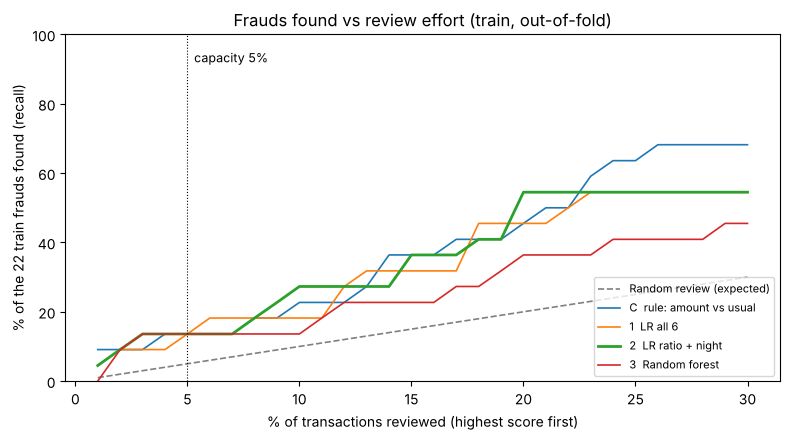

In [25]:
caps = np.arange(0.01, 0.31, 0.01)
curves = {'Random review (expected)': caps,
          'C  rule: amount vs usual': [capacity_metrics(y_tr, rule_score, c)['recall'] for c in caps],
          '1  LR all 6': [capacity_metrics(y_tr, oof_store[('LR all 6', best_C1)], c)['recall'] for c in caps],
          '2  LR ratio + night': [capacity_metrics(y_tr, oof_store[('LR ratio + night', best_C2)], c)['recall'] for c in caps],
          '3  Random forest': [capacity_metrics(y_tr, oof_store[('Random forest', best_rf)], c)['recall'] for c in caps]}
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, rec in curves.items():
    ax.plot(100 * caps, 100 * np.asarray(rec), lw=2 if name.startswith('2') else 1.2,
            ls='--' if name.startswith('Random') else '-', color='grey' if name.startswith('Random') else None, label=name)
ax.axvline(5, color='black', lw=0.8, ls=':')
ax.text(5.3, 92, 'capacity 5%', fontsize=9)
ax.set_xlabel('% of transactions reviewed (highest score first)')
ax.set_ylabel('% of the 22 train frauds found (recall)')
ax.set_title('Frauds found vs review effort (train, out-of-fold)')
ax.set_ylim(0, 100)
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

**What the output shows**
- **[Data]** At the 5% capacity every method finds 3 of the 22 train frauds (recall 13.6%, precision 2.7%, 112 reviews). Random review expects 1.1; "all legitimate" finds 0.
- **[Data]** Is that more than luck? For candidate 2: at 5%, random review finds 3 or more 9.5% of the time (p = 0.095 > 0.05), so at the chosen capacity the gain over random is **not statistically significant**. At 10% capacity it finds 6 of 22 vs 2.2 expected, and random reaches 6 or more only 1.8% of the time (p = 0.018 < 0.05).
- **[Data]** The rule (C) and candidate 2 are practically the same: equal at 2% and 5%, 5 vs 6 frauds at 10%, ROC AUC 0.707 vs 0.683.

**[Choice] Selected candidate: candidate 2 – logistic regression with `log_amount_vs_usual` + `night`, C = 0.01.**
- It is equal-best at 5% and the best at 10% (selection rule from 4.3).
- It is the simplest model (2 weights), so it is the easiest to explain and the least likely to overfit.
- It uses one feature more than the rule (night), which Phase 2 supported; whether that adds anything real is a question for the test set.

**Honest limits of this choice**
- **The model has not been shown to beat the simple rule.** In Phase 5 the rule must therefore stay in the comparison: if the model does not beat it on test, the rule is the better choice because it is simpler.
- Differences of 1 fraud are noise (one fraud = 4.5 points of recall here, 10 points on the 10-fraud test set).
- We compared 14 settings on the same 22 frauds; picking the best of many always flatters the winner a little. This is one more reason to use the sealed test set only once.

The plot shows the same story for every review effort from 1% to 30%: all methods lie above the random line (grey) almost everywhere, and the lines cross each other many times, so no model is consistently better than the rule.

### 4.8 Final model: refit on all of train

After choosing the settings, the model is trained once more on **the whole train set** (Modelling class 5, "training the final model"): cross-validation was only to choose; the final model should learn from all 22 frauds. The test set is still not touched.

We also save the **score cutoff**: the score of the last transaction that falls inside the top 5% of train. Phase 1 (criterion 3) asks that the cutoff behaves similarly in train and test; Phase 5 checks what share of test transactions lands above it.

In [26]:
final_model = Pipeline([('prep', ColumnTransformer([
                            ('continuous', Pipeline([('impute', SimpleImputer(strategy='median')),
                                                     ('scale', StandardScaler())]), ['log_amount_vs_usual']),
                            ('binary', 'passthrough', ['night'])])),
                        ('model', LogisticRegression(C=best_C2, max_iter=1000))])
final_model.fit(X_model[features_small], y_tr)        # <- the whole TRAIN set, never the test set

lr = final_model.named_steps['model']
print('Final model: logistic regression, C = %s, features = %s' % (best_C2, features_small))
print('  intercept: %.3f' % lr.intercept_[0])
for name, w in zip(features_small, lr.coef_[0]):
    print('  weight %-20s: %+.3f' % (name, w))

train_scores = final_model.predict_proba(X_model[features_small])[:, 1]
cutoff = np.sort(train_scores)[::-1][int(round(CAPACITY * len(train_scores))) - 1]
print('\nScore cutoff for the 5%% review list (from the train scores): %.4f' % cutoff)
print('Share of train transactions at or above the cutoff: %.1f%%' % (100 * (train_scores >= cutoff).mean()))
print('Highest / median / lowest train score: %.4f / %.4f / %.4f' % (train_scores.max(), np.median(train_scores), train_scores.min()))
print('\nExample - two transactions that differ only in night (ratio = 3x the usual amount):')
example = pd.DataFrame({'log_amount_vs_usual': [np.log(3), np.log(3)], 'night': [0, 1]})
print('  daytime score: %.4f | night score: %.4f' % tuple(final_model.predict_proba(example)[:, 1]))

Final model: logistic regression, C = 0.01, features = ['log_amount_vs_usual', 'night']
  intercept: -4.628
  weight log_amount_vs_usual : +0.127
  weight night               : +0.034

Score cutoff for the 5% review list (from the train scores): 0.0121
Share of train transactions at or above the cutoff: 5.0%
Highest / median / lowest train score: 0.0151 / 0.0098 / 0.0063

Example - two transactions that differ only in night (ratio = 3x the usual amount):
  daytime score: 0.0106 | night score: 0.0110


**What the output shows**
- **[Data]** Both weights are positive: a higher amount compared with usual spending and a night-time transaction both raise the score. The direction matches Phase 2. The amount ratio counts most (weight +0.127 per standard deviation vs +0.034 for night), so the model ranks almost entirely by the same ratio as rule C, which explains why the two behave alike.
- **[Data]** The weights are small because C = 0.01 restrains them strongly. As a result all scores stay close to the 1% fraud rate (0.0063 to 0.0151). **The scores are a ranking, not reliable probabilities:** a score of 0.012 should not be read as "1.2% chance of fraud". For our use (ordering the review list) only the order matters.
- **[Data]** The 5% cutoff on train is 0.0121; exactly 5.0% of train transactions are at or above it.
- **[Data]** The example shows the size of the night effect: at 3× the usual amount, night moves the score only from 0.0106 to 0.0110.

### 4.9 Decision log

| # | Decision | Evidence | Technique | Check |
|---|---|---|---|---|
| 1 | Measure frauds found in the top 5% (recall, precision), not accuracy | 1% fraud; 5% capacity (Phase 1); Baseline A 99.0% accurate with 0 frauds found | rank by score, flag top 5%, confusion matrix | demo by hand: recall 0.5, precision 0.5 as expected |
| 2 | Three baselines: all-legitimate, random review, ratio rule | Phase 1 criteria; ratio was the strongest signal in 2.5 | majority class; binomial n = 22, p = 0.05; sort by ratio | random expects 1.1 frauds; ≥ 4 needed for p < 0.05; rule finds 3 |
| 3 | Stratified 5-fold CV inside train, preprocessing refitted per fold | 22 frauds; test must stay sealed | `StratifiedKFold`, `Pipeline` | 4–5 frauds per fold; test never used |
| 4 | Logistic regression, C tuned by grid search | binary target, few frauds, explainability | C ∈ {0.01, 0.1, 1, 10} | all 6 features: 3/22 at 5%; larger C → lower AUC (overfitting) |
| 5 | Drop the 4 weak features | equal medians (2.5); candidate 1 not better than rule | logistic regression on ratio + night | 3/22 at 5%, 6/22 at 10%, AUC 0.683 |
| 6 | Random forest only as a comparison | test for non-linear patterns | grid on depth and min split | best 3/22 at 5%, AUC 0.618; deepest trees AUC 0.499 |
| 7 | Select candidate 2, refit on all train | selection rule 4.3; simplest equal-best model | `fit` on 2,240 rows | weights positive; 5% cutoff 0.0121 |

### 4.10 What Phase 4 hands over to Phase 5

- `final_model` (fitted on train) with `features_small` = ['log_amount_vs_usual', 'night'], and the 5% score `cutoff`.
- The baselines that Phase 5 must compare against on the test set: **random review** (expects 0.5 of the 10 test frauds at 5%), **rule C** (sort by amount vs usual) and **"all legitimate"**.
- `X_test_f`, `y_test` and `loss_test`, still unused.

**Next decisions for Phase 5:** score the test set once; count frauds found and false alarms at 2%, 5% and 10% for the model and every baseline; check whether about 5% of test transactions land above the cutoff; express missed fraud in euros with `loss_test`; inspect errors by country and channel; then decide (deploy / pilot / collect more data / revise).

**Limitations carried forward:** cross-validation shows only a weak signal (3 of 22 frauds at 5%, not significant vs random at that capacity; significant at 10%); the model is not better than a simple rule; only 10 test frauds, so test results will be very noisy; the label is chargeback-confirmed fraud; no timestamp to test stability over time.